# GDP growth: autoregressive dynamics and forecasting

Compare quarterly real GDP growth in the **United States, Germany and Italy**.
Use ACF and PACF plots, choose an AR order, estimate persistence and examine
what the fitted dynamics imply about oscillations. Evaluate one-step forecasts
on held-out quarters and then produce forecasts beyond the dataset's endpoint.

The common growth sample is **1996Q2-2025Q4 (119 quarters)**. The first GDP
level, 1996Q1, supplies the growth base. All data are included locally.

Data Sources:

- BEA [US real GDP, GDPC1](https://fred.stlouisfed.org/series/GDPC1), through FRED.
- [Eurostat quarterly national accounts, `namq_10_gdp`](https://ec.europa.eu/eurostat/databrowser/view/namq_10_gdp/default/table?lang=en):
  Germany and Italy, chain-linked volumes (2020), seasonally and calendar adjusted.

These are revised values available on 13 October 2026, restricted to a common
endpoint in 2025. Forecasts here are historical teaching exercises, not a
current economic outlook or a replication of real-time forecasts.

## Environment setup

**Colab:** upload the complete `Notebooks` folder to **My Drive**, keeping the
subfolders and CSV files. Run the cell below and authorize Drive access.
**Local Jupyter:** keep the same folder structure and run the cell below.
If the folder is elsewhere, set `NOTEBOOKS_ROOT` to its full path.


In [1]:
from pathlib import Path

# Usually leave this as None. If needed, enter the path to the folder
# containing all tutorial subfolders (Google Drive or the Colab runtime).
NOTEBOOKS_ROOT = None
TUTORIAL = "Time_Series"

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    notebooks_root = Path(NOTEBOOKS_ROOT or "/content/drive/MyDrive/Notebooks")
    if notebooks_root.is_relative_to("/content/drive"):
        drive.mount("/content/drive")
else:
    if NOTEBOOKS_ROOT is not None:
        notebooks_root = Path(NOTEBOOKS_ROOT).expanduser().resolve()
    else:
        # Work from the tutorial folder, Notebooks, or the course folder.
        here = Path.cwd().resolve()
        candidates = [here, *here.parents]
        candidates += [parent / "Notebooks" for parent in [here, *here.parents]]
        notebooks_root = next(
            (root for root in candidates if (root / TUTORIAL).is_dir()), here
        )

DATA_DIR = notebooks_root / TUTORIAL
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Tutorial folder not found: {DATA_DIR}. "
        "Upload the complete Notebooks folder to My Drive, or set "
        "NOTEBOOKS_ROOT to the folder containing the tutorial subfolders."
    )
print(f"Data folder found: {DATA_DIR.name}")

Data folder found: Time_Series


## Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from IPython.display import display

## Data and quarterly growth

For positive real GDP $Y_t$, calculate quarterly log growth:

$$g_t=100\,[\log(Y_t)-\log(Y_{t-1})].$$

Growth is approximately a percentage change **from one quarter to the next**,
without annualisation. A value of 1 means approximately 1% quarterly growth.
The US GDP level is reported at an annual rate; its constant scaling cancels
in the growth calculation. Different currencies, scale factors and reference
years prevent direct comparisons of the level magnitudes, but do not prevent
comparisons of these growth rates. Rebase the levels to 100 for visual comparison.

The common sample starts in 1996 because this Eurostat extract has no Italian
observations for 1995. Do not impute those quarters. Eurostat marks German
observations from 2023Q1 as provisional and Italian 2010Q1 as a break in the
time series. Retain and disclose these source flags; a constant-parameter AR
model need not capture every source change or structural shift.

In [3]:
levels = pd.read_csv(DATA_DIR / "quarterly_real_gdp.csv", index_col="quarter")
levels.index = pd.PeriodIndex(levels.index, freq="Q")
countries = ["United States", "Germany", "Italy"]
if list(levels.columns) != countries or levels.isna().any().any() or not levels.gt(0).all().all():
    raise ValueError("Inspect the GDP columns, missing observations and positive levels.")
if not levels.index.equals(pd.period_range(levels.index[0], levels.index[-1], freq="Q")):
    raise ValueError("Missing, duplicate or unordered quarters: do not treat gaps as adjacent observations.")
growth = (100 * np.log(levels).diff()).iloc[1:]
indexed_gdp = 100 * levels / levels.iloc[0]
colors = {"United States": "#244c78", "Germany": "#ac6740", "Italy": "#3a8069"}
print(f"Growth sample: {growth.index[0]} to {growth.index[-1]}, {len(growth)} quarters per country")
display(growth.head().round(3))

Growth sample: 1996Q2 to 2025Q4, 119 quarters per country


,United States,Germany,Italy
quarter,,,
1996Q2,1.654,1.408,0.083
1996Q3,0.893,0.349,0.181
1996Q4,1.033,0.933,-0.356
1997Q1,0.643,-0.522,0.266
1997Q2,1.652,1.154,1.696


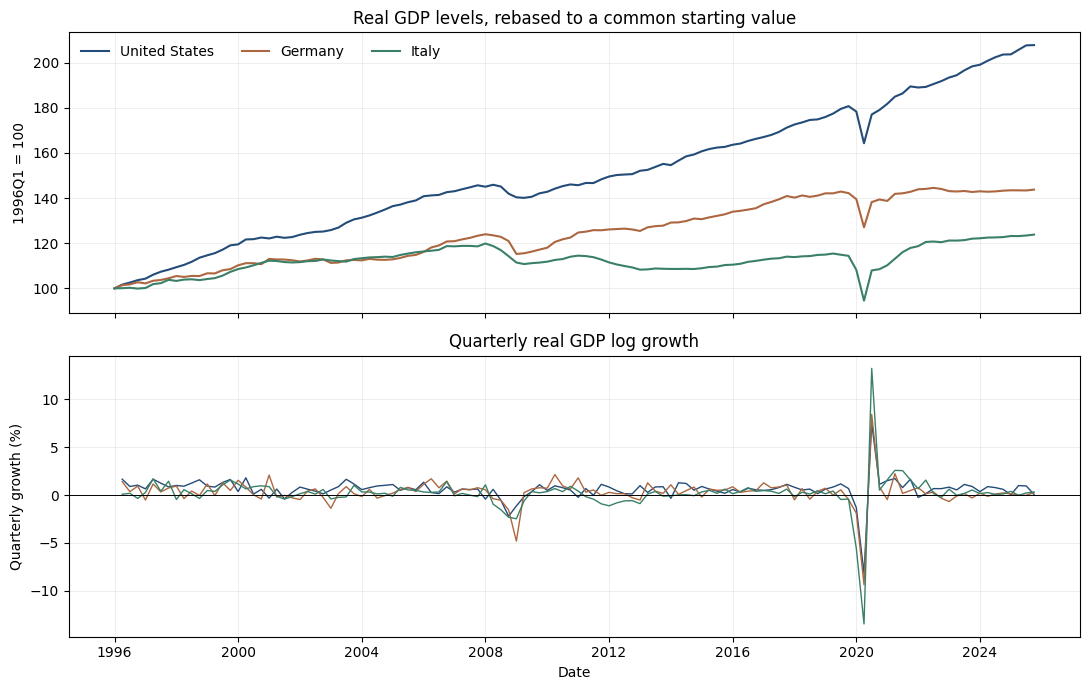

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for country in countries:
    axes[0].plot(indexed_gdp.index.to_timestamp(), indexed_gdp[country], color=colors[country], label=country)
    axes[1].plot(growth.index.to_timestamp(), growth[country], color=colors[country], linewidth=1)
axes[0].set(title="Real GDP levels, rebased to a common starting value", ylabel="1996Q1 = 100")
axes[0].legend(frameon=False, ncol=3)
axes[1].set(title="Quarterly real GDP log growth", ylabel="Quarterly growth (%)", xlabel="Date")
axes[1].axhline(0, color="black", linewidth=0.7)
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

GDP levels trend over time, while growth fluctuates around a much more stable
scale. Differencing helps remove the level trend; it does **not prove weak
stationarity**. The 2020 contraction and rebound are unusually large, and may
have a substantial influence on autocorrelations and AR estimates. The main
analysis retains them. A separate, contiguous sample ending in 2019 assesses
how sensitive the conclusions are to the sample endpoint; no quarters are
deleted from the middle of a lagged series.

## ACF and PACF

The ACF measures correlation between $g_t$ and $g_{t-k}$. The PACF measures
their linear association after controlling for the intermediate lags. For a
stationary population AR($p$), the PACF cuts off after lag $p$, while the ACF
usually decays. Finite-sample plots are noisy, so a crossing is a clue rather
than an automatic order-selection rule. Each lag is one quarter.

The ACF uses approximate white-noise bands and the PACF uses approximate
pointwise bands. These are descriptive guides, not simultaneous tests or
evidence that the growth series is stationary.

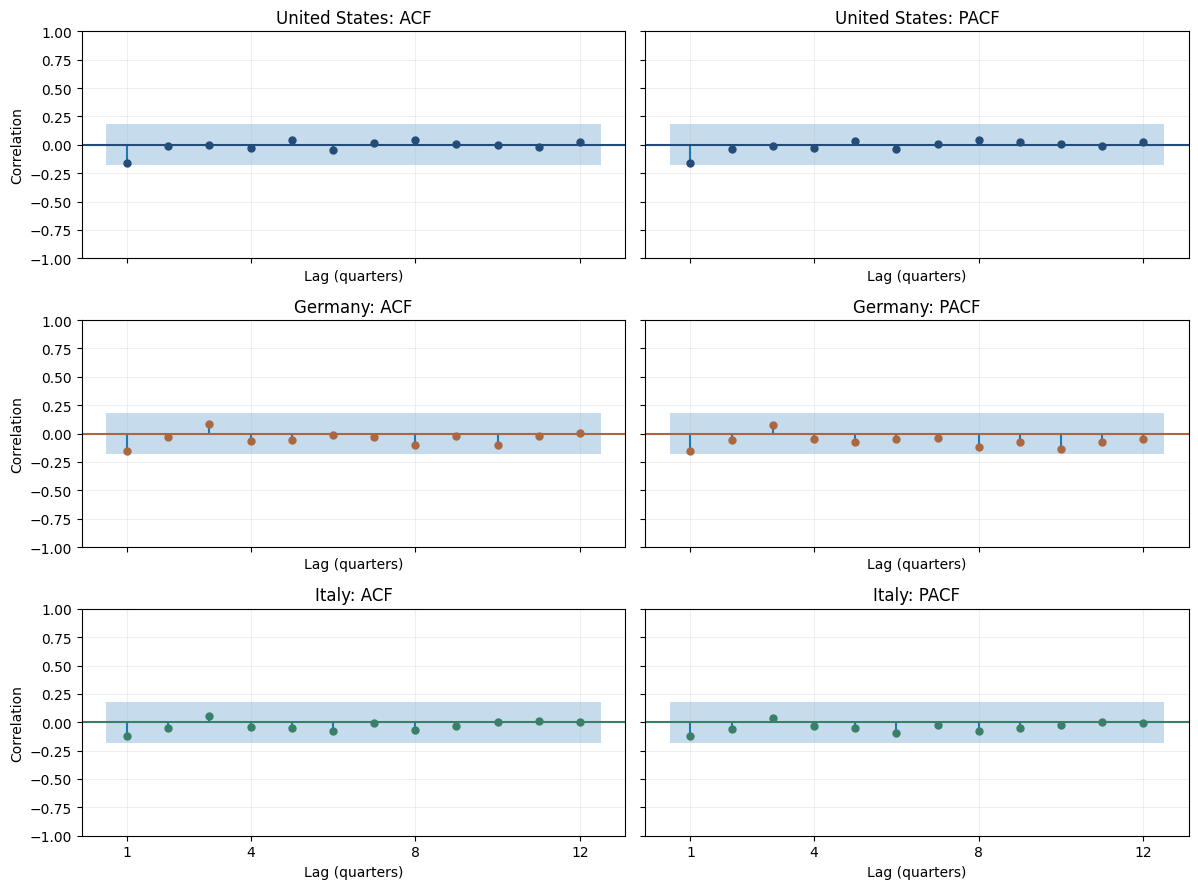

In [5]:
fig, axes = plt.subplots(len(countries), 2, figsize=(12, 9), sharex=True, sharey=True)
for row, country in enumerate(countries):
    plot_acf(growth[country], lags=12, zero=False, bartlett_confint=False,
             ax=axes[row, 0], color=colors[country])
    plot_pacf(growth[country], lags=12, zero=False, method="ywm",
              ax=axes[row, 1], color=colors[country])
    for col, name in enumerate(["ACF", "PACF"]):
        axes[row, col].set(title=f"{country}: {name}", xlabel="Lag (quarters)")
        axes[row, col].set_xticks([1, 4, 8, 12])
        axes[row, col].grid(alpha=0.2)
    axes[row, 0].set_ylabel("Correlation")
fig.tight_layout()
plt.show()

## Choosing an AR order on a common sample

Estimate the constant-mean autoregression

$$g_t=c+\phi_1g_{t-1}+\cdots+\phi_pg_{t-p}+u_t.$$

Compare contiguous lag orders $p=0,\ldots,8$ using OLS (conditional Gaussian
likelihood). AR(0) is an intercept-only benchmark; it is a valid selection
outcome. The eight-quarter maximum is a teaching choice, not a known true order.
Use `hold_back=8` for **every candidate**, so all nine models use the same
dependent-variable observations, starting in 1998Q2.

$$\mathrm{AIC}=-2\ell+2K,\qquad
\mathrm{BIC}=-2\ell+K\log n.$$

Here $K=p+2$ counts the intercept, $p$ lag coefficients and the innovation
variance in statsmodels' Gaussian likelihood convention. Smaller is better.
BIC imposes a larger complexity penalty for these sample sizes. Select BIC
for the main model and report AIC as a comparison. Neither criterion proves
that the selected model is correct or that it will forecast well.

In [6]:
MAX_ORDER = 8

def fit_candidates(y):
    models = {p: AutoReg(y, lags=p, trend="c", hold_back=MAX_ORDER).fit()
              for p in range(MAX_ORDER + 1)}
    table = pd.DataFrame({p: {"n": int(model.nobs), "AIC": model.aic, "BIC": model.bic}
                          for p, model in models.items()}).T
    table.index.name = "p"
    selected_p = int(table["BIC"].idxmin())
    return models, table, selected_p

candidate_models, criteria, selected_order, fitted = {}, {}, {}, {}
selection_rows = []
for country in countries:
    models, table, p = fit_candidates(growth[country])
    candidate_models[country], criteria[country], selected_order[country] = models, table, p
    fitted[country] = models[p]
    selection_rows.append({"Country": country, "BIC order": p,
                           "AIC order": int(table["AIC"].idxmin()), "Estimation n": int(models[p].nobs)})
selection = pd.DataFrame(selection_rows).set_index("Country")
display(selection)
display(pd.concat({country: criteria[country][["AIC", "BIC"]] for country in countries}, axis=1).round(2))

,BIC order,AIC order,Estimation n
Country,,,
United States,0,1,111
Germany,0,1,111
Italy,0,0,111


United States         Germany           Italy        
            AIC     BIC     AIC     BIC     AIC     BIC
p                                                      
0        362.66  368.08  402.77  408.19  473.93  479.34
1        361.46  369.59  402.07  410.20  474.35  482.48
2        363.17  374.00  403.60  414.44  475.86  486.70
3        365.13  378.68  404.95  418.50  477.67  491.21
4        366.94  383.20  406.70  422.96  479.58  495.83
5        368.86  387.82  408.04  427.00  481.24  500.21
6        370.68  392.36  409.71  431.39  482.21  503.89
7        372.68  397.06  411.48  435.86  484.13  508.51
8        374.49  401.58  411.91  439.00  485.47  512.56

On this full sample, **BIC chooses AR(0) for all three countries**. The large
2020 movements do not translate into a clear improvement from adding constant
linear lag coefficients under this penalty. This outcome does not establish
independence or an absence of economic dynamics. It says that these additional
lags are not selected within this candidate family and sample.

Keep AR(1) as a transparent persistence benchmark, and AR(2) as a separate
illustration of how oscillations would be diagnosed. Neither benchmark
replaces the BIC-selected model simply to obtain a cycle.

## Coefficients, long-run means and residuals

$c$ is measured in percent per quarter; each $\phi_j$ is dimensionless. In an
AR(1), $\phi_1$ is the next-quarter effect of a one-percentage-point innovation
in growth, under the fitted dynamics. Positive values imply same-direction
propagation; negative values imply reversal. For a stable AR($p$),

$$\mu=\frac{c}{1-\sum_{j=1}^{p}\phi_j}.$$

The intercept is the conditional fitted growth when all included lagged growth
rates equal zero; it is generally **not** the long-run mean. AR(0) has $\mu=c$.
The coefficient table includes the selected model and the AR(1) benchmark.
Standard errors, p-values and intervals use conventional conditional Gaussian
inference. They do not account for order selection, changing variance or breaks.

In [7]:
coefficient_rows = []
for country in countries:
    orders = sorted({selected_order[country], 1})
    for p in orders:
        result = candidate_models[country][p]
        ci = np.asarray(result.conf_int(alpha=0.05))
        for j, (term, estimate) in enumerate(result.params.items()):
            coefficient_rows.append({"Country": country, "Model": f"AR({p})", "Term": term,
                                     "Estimate": estimate, "SE": result.bse.iloc[j],
                                     "p-value": result.pvalues.iloc[j],
                                     "95% lower": ci[j, 0], "95% upper": ci[j, 1]})
coefficients = pd.DataFrame(coefficient_rows).set_index(["Country", "Model", "Term"])
display(coefficients.round(4))

diagnostic_rows = []
for country, result in fitted.items():
    p = selected_order[country]
    eigenvalues = 1 / result.roots if p else np.array([])
    stable = bool(np.all(np.abs(eigenvalues) < 1))
    phi = result.params.iloc[1:].to_numpy()
    test = acorr_ljungbox(result.resid, lags=[12], model_df=p, return_df=True).iloc[0]
    diagnostic_rows.append({"Country": country, "p": p, "Stable": stable,
                            "Long-run mean (%)": result.params.iloc[0] / (1 - phi.sum()) if stable else np.nan,
                            "Residual Q(12)": test["lb_stat"], "Reference df": 12 - p,
                            "Residual p-value": test["lb_pvalue"]})
diagnostics = pd.DataFrame(diagnostic_rows).set_index("Country")
display(diagnostics.round(4))

Estimate      SE  p-value  95% lower  \
Country       Model Term                                                     
United States AR(0) const               0.5778  0.1155   0.0000     0.3514   
              AR(1) const               0.6768  0.1264   0.0000     0.4290   
                    United States.L1   -0.1687  0.0936   0.0714    -0.3522   
Germany       AR(0) const               0.2789  0.1384   0.0439     0.0076   
              AR(1) const               0.3231  0.1393   0.0204     0.0500   
                    Germany.L1         -0.1549  0.0937   0.0982    -0.3385   
Italy         AR(0) const               0.1631  0.1907   0.3925    -0.2107   
              AR(1) const               0.1816  0.1899   0.3390    -0.1907   
                    Italy.L1           -0.1187  0.0942   0.2078    -0.3033   

                                      95% upper  
Country       Model Term                         
United States AR(0) const                0.8043  
              AR(1) const                0.9245  
                    United States.L1     0.0147  
Germany       AR(0) const                0.5502  
              AR(1) const                0.5962  
                    Germany.L1           0.0287  
Italy         AR(0) const                0.5369  
              AR(1) const                0.5539  
                    Italy.L1             0.0660

,p,Stable,Long-run mean (%),Residual Q(12),Reference df,Residual p-value
Country,,,,,,
United States,0,True,0.5778,4.3643,12,0.9759
Germany,0,True,0.2789,7.9713,12,0.7874
Italy,0,True,0.1631,4.1495,12,0.9806


The residual Ljung-Box null is zero residual autocorrelation at lags 1 through
12. Its approximate reference has $12-p$ degrees of freedom, adjusting for
the estimated AR coefficients. A small p-value suggests remaining linear
dependence and a need to reconsider the specification. A large p-value does
not validate every model assumption. This usual reference also has limitations
under changing variance and after order selection.

## Sensitivity to the sample endpoint

In [8]:
pre_covid = growth.loc[:"2019Q4"]
pre_fitted, pre_candidates, pre_order = {}, {}, {}
sensitivity_rows = []
for country in countries:
    models, table, p = fit_candidates(pre_covid[country])
    pre_candidates[country], pre_fitted[country], pre_order[country] = models, models[p], p
    for label, y, pool, order in [("Through 2019Q4", pre_covid[country], models, p),
                                  ("Through 2025Q4", growth[country], candidate_models[country], selected_order[country])]:
        ar1 = pool[1]
        sensitivity_rows.append({"Country": country, "Sample end": label,
                                 "Growth quarters": len(y), "Estimation n": int(pool[order].nobs),
                                 "BIC order": order, "AIC order": min(pool, key=lambda k: pool[k].aic),
                                 "AR(1) coefficient": ar1.params.iloc[1]})
sensitivity = pd.DataFrame(sensitivity_rows).set_index(["Country", "Sample end"])
display(sensitivity.round(4))

Growth quarters  Estimation n  BIC order  \
Country       Sample end                                                 
United States Through 2019Q4               95            87          1   
              Through 2025Q4              119           111          0   
Germany       Through 2019Q4               95            87          1   
              Through 2025Q4              119           111          0   
Italy         Through 2019Q4               95            87          1   
              Through 2025Q4              119           111          0   

                              AIC order  AR(1) coefficient  
Country       Sample end                                    
United States Through 2019Q4          2             0.3724  
              Through 2025Q4          1            -0.1687  
Germany       Through 2019Q4          1             0.2358  
              Through 2025Q4          1            -0.1549  
Italy         Through 2019Q4          1             0.6198  
              Through 2025Q4          0            -0.1187

BIC selects **AR(1) in each country through 2019**, with positive persistence,
whereas the full-sample AR(1) coefficients are negative. The two samples differ
in length and in all observations added after 2019; this comparison cannot
attribute every difference solely to the pandemic or establish a structural
break. It demonstrates that a persistence estimate depends on the sample.

Keep both samples contiguous. Deleting 2020 and concatenating 2019 with 2021
would incorrectly treat non-adjacent quarters as adjacent lags.

## Shock propagation and oscillations

For a one-percentage-point **reduced-form innovation** at quarter zero, the
growth impulse response is computed recursively:

$$\psi_0=1,\qquad \psi_h=\sum_{j=1}^{\min(p,h)}\phi_j\psi_{h-j}.$$

AR(0) has no propagation beyond the initial quarter. AR(1) has
$\psi_h=\phi_1^h$: positive persistence produces smooth decay, while a negative
coefficient alternates signs every quarter. This is not an identified causal
effect of a policy shock. An eventual return of **growth** to its mean also
does not imply that the **GDP level** returns to its previous path.

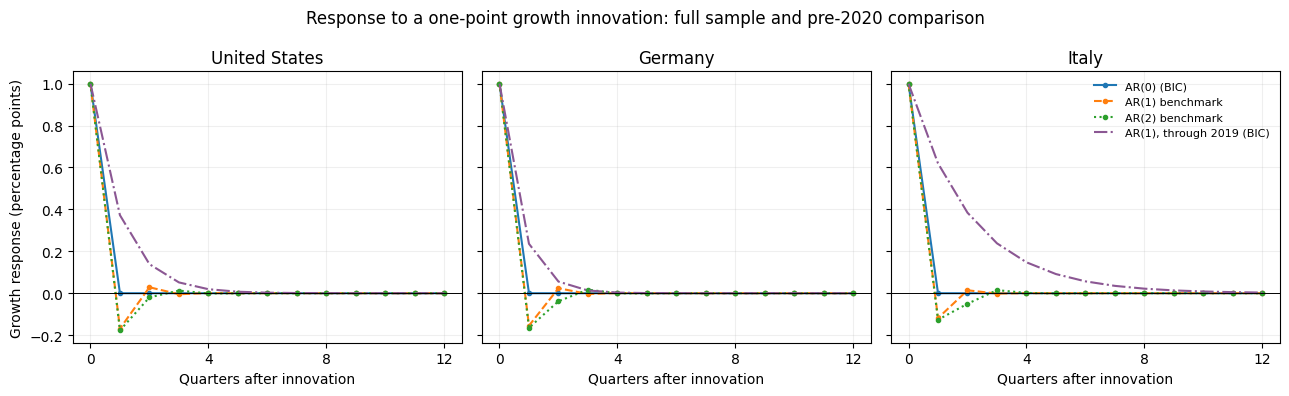

In [9]:
def impulse_response(result, horizon=24):
    phi = result.params.iloc[1:].to_numpy()
    response = np.zeros(horizon + 1)
    response[0] = 1
    for h in range(1, horizon + 1):
        response[h] = sum(phi[j - 1] * response[h - j] for j in range(1, min(len(phi), h) + 1))
    return response

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for ax, country in zip(axes, countries):
    for p, style in [(selected_order[country], "-"), (1, "--"), (2, ":")]:
        label = f"AR({p})" + (" (BIC)" if p == selected_order[country] else " benchmark")
        response = impulse_response(candidate_models[country][p], horizon=12)
        ax.plot(range(13), response, linestyle=style, marker="o", markersize=3, label=label)
    ax.plot(range(13), impulse_response(pre_fitted[country], horizon=12),
            color="#8b5793", linestyle="-.", label="AR(1), through 2019 (BIC)")
    ax.axhline(0, color="black", linewidth=0.7)
    ax.set(title=country, xlabel="Quarters after innovation")
    ax.set_xticks([0, 4, 8, 12])
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Growth response (percentage points)")
axes[-1].legend(frameon=False, fontsize=8)
fig.suptitle("Response to a one-point growth innovation: full sample and pre-2020 comparison")
fig.tight_layout()
plt.show()

## Can an AR model estimate an average business-cycle length?

An order greater than one does **not** automatically imply a cycle. For AR(2),
the dynamic eigenvalues solve $\lambda^2-\phi_1\lambda-\phi_2=0$.
They form a complex conjugate pair if $\phi_1^2+4\phi_2<0$.
Writing a stable pair as $\lambda=r e^{\pm i\theta}$ gives

$$P=\frac{2\pi}{|\theta|}\quad\text{quarters},\qquad
P_{\mathrm{years}}=\frac{P}{4},\qquad
H_{1/2}=\frac{\log(0.5)}{\log(r)}\quad\text{quarters}.$$

$P$ is the period of a **model-implied damped oscillatory mode**.
$H_{1/2}$ measures halving of its exponential envelope, not a guaranteed
halving time for the full impulse response. Stability requires all dynamic
eigenvalues to have modulus below one. The `roots` reported by statsmodels
are the lag-polynomial roots, so invert them to obtain these eigenvalues.
For an AR($p$), several modes can exist; a real dominant mode or rapid damping
can prevent a sustained oscillation even if a complex pair is present.

Positive real eigenvalues describe monotone decay. Negative real eigenvalues
can produce quarter-by-quarter sign alternation, not a multi-year cycle.
AR(0) has no dynamic modes. Inspect the BIC-selected models and an explicitly
labelled AR(2) benchmark on both samples, rather than imposing an order to
produce a desired duration.

In [10]:
def dynamic_modes(result):
    phi = result.params.iloc[1:].to_numpy()
    if len(phi) == 0:
        return [{"Mode": "No dynamic mode", "Modulus": np.nan,
                 "Period (years)": np.nan, "Envelope half-life (q)": np.nan}]
    eigen = 1 / np.asarray(result.roots, dtype=complex)
    rows = []
    # Keep one member of each conjugate pair; keep every real eigenvalue.
    for value in sorted(eigen, key=lambda z: abs(z), reverse=True):
        if value.imag < -1e-8:
            continue
        radius = abs(value)
        oscillatory = abs(value.imag) > 1e-8
        stable = 0 < radius < 1
        rows.append({"Mode": "Complex pair" if oscillatory else ("Real positive" if value.real >= 0 else "Real negative"),
                     "Modulus": radius,
                     "Period (years)": 2 * np.pi / abs(np.angle(value)) / 4 if oscillatory and stable else np.nan,
                     "Envelope half-life (q)": np.log(0.5) / np.log(radius) if stable else np.nan})
    return rows

mode_rows = []
for country in countries:
    for label, pool, order in [("Through 2019Q4", pre_candidates[country], pre_order[country]),
                               ("Through 2025Q4", candidate_models[country], selected_order[country])]:
        for p in sorted({order, 2}):
            model_stable = bool(np.all(np.abs(pool[p].roots) > 1)) if p else True
            for row in dynamic_modes(pool[p]):
                mode_rows.append({"Country": country, "Sample end": label,
                                  "Model": f"AR({p})" + (" (BIC)" if p == order else " benchmark"),
                                  "All modes stable": model_stable, **row})
modes = pd.DataFrame(mode_rows).set_index(["Country", "Sample end", "Model"])
display(modes.round(3))

All modes stable  \
Country       Sample end     Model                               
United States Through 2019Q4 AR(1) (BIC)                  True   
                             AR(2) benchmark              True   
                             AR(2) benchmark              True   
              Through 2025Q4 AR(0) (BIC)                  True   
                             AR(2) benchmark              True   
Germany       Through 2019Q4 AR(1) (BIC)                  True   
                             AR(2) benchmark              True   
                             AR(2) benchmark              True   
              Through 2025Q4 AR(0) (BIC)                  True   
                             AR(2) benchmark              True   
Italy         Through 2019Q4 AR(1) (BIC)                  True   
                             AR(2) benchmark              True   
                             AR(2) benchmark              True   
              Through 2025Q4 AR(0) (BIC)                  True   
                             AR(2) benchmark              True   

                                                         Mode  Modulus  \
Country       Sample end     Model                                       
United States Through 2019Q4 AR(1) (BIC)        Real positive    0.372   
                             AR(2) benchmark    Real positive    0.614   
                             AR(2) benchmark    Real negative    0.314   
              Through 2025Q4 AR(0) (BIC)      No dynamic mode      NaN   
                             AR(2) benchmark     Complex pair    0.226   
Germany       Through 2019Q4 AR(1) (BIC)        Real positive    0.236   
                             AR(2) benchmark    Real positive    0.449   
                             AR(2) benchmark    Real negative    0.240   
              Through 2025Q4 AR(0) (BIC)      No dynamic mode      NaN   
                             AR(2) benchmark     Complex pair    0.256   
Italy         Through 2019Q4 AR(1) (BIC)        Real positive    0.620   
                             AR(2) benchmark    Real positive    0.676   
                             AR(2) benchmark    Real negative    0.093   
              Through 2025Q4 AR(0) (BIC)      No dynamic mode      NaN   
                             AR(2) benchmark     Complex pair    0.257   

                                              Period (years)  \
Country       Sample end     Model                             
United States Through 2019Q4 AR(1) (BIC)                 NaN   
                             AR(2) benchmark             NaN   
                             AR(2) benchmark             NaN   
              Through 2025Q4 AR(0) (BIC)                 NaN   
                             AR(2) benchmark           0.796   
Germany       Through 2019Q4 AR(1) (BIC)                 NaN   
                             AR(2) benchmark             NaN   
                             AR(2) benchmark             NaN   
              Through 2025Q4 AR(0) (BIC)                 NaN   
                             AR(2) benchmark           0.827   
Italy         Through 2019Q4 AR(1) (BIC)                 NaN   
                             AR(2) benchmark             NaN   
                             AR(2) benchmark             NaN   
              Through 2025Q4 AR(0) (BIC)                 NaN   
                             AR(2) benchmark           0.863   

                                              Envelope half-life (q)  
Country       Sample end     Model                                    
United States Through 2019Q4 AR(1) (BIC)                       0.702  
                             AR(2) benchmark                   1.421  
                             AR(2) benchmark                   0.598  
              Through 2025Q4 AR(0) (BIC)                         NaN  
                             AR(2) benchmark                   0.467  
Germany       Through 2019Q4 AR(1) (BIC)                       0.480  
       

The selected full-sample AR(0) models have no dynamic cycle, and the selected
pre-2020 AR(1) models describe positive decay. The full-sample AR(2) benchmarks
have complex pairs, but their implied periods are **less than one year**, with
envelopes that halve in **less than one quarter**. The pre-2020 AR(2) benchmarks
have real eigenvalues. These results provide no persuasive estimate of a
sustained, multi-year average business cycle from these growth autoregressions.

Averaging those short AR(2) periods across countries would not estimate an
average business-cycle duration. They are unselected, sample-sensitive
oscillatory modes, without an uncertainty interval here. Estimating actual
expansion/recession durations or a cycle around trend would require a
different definition and method. Growth dynamics, deviations of GDP from
trend, and dated business-cycle turning points are distinct objects.

## One-step forecasts on held-out quarters

Hold out **2024Q1-2025Q4 (eight quarters)**. Choose $p$ and estimate coefficients
using data through **2023Q4 only**. Freeze those coefficients and generate
one-step forecasts sequentially:

$$\widehat g_{t|t-1}=\widehat c+\sum_{j=1}^{p}\widehat\phi_j g_{t-j}.$$

Each quarter's forecast uses only growth observations already available before
that quarter, including previously observed holdout quarters. These are eight
successive **one-step** forecasts, not an eight-step forecast from one origin.
Compare with an expanding historical-mean forecast and a last-observation
forecast. None uses the current quarter's outcome. Report MAE and RMSE in
percentage points; eight errors offer only limited evidence of forecast quality.
All values are current-vintage revisions, so this is a pseudo-out-of-sample
exercise rather than a real-time evaluation.

In [11]:
train = growth.loc[:"2023Q4"]
test = growth.loc["2024Q1":]
forecast_rows, evaluation_rows, training_models = [], [], {}
for country in countries:
    models, table, p = fit_candidates(train[country])
    model = models[p]
    training_models[country] = model
    history = train[country].to_list()
    phi = model.params.iloc[1:].to_numpy()
    for quarter, actual in test[country].items():
        ar_forecast = model.params.iloc[0] + sum(phi[j - 1] * history[-j] for j in range(1, p + 1))
        forecast_rows.append({"Country": country, "Quarter": quarter, "Actual": actual,
                              "AR forecast": ar_forecast, "Historical mean": np.mean(history),
                              "Last observation": history[-1]})
        history.append(actual)  # Only after forecasting this quarter.
    country_forecasts = pd.DataFrame([row for row in forecast_rows if row["Country"] == country])
    for method in ["AR forecast", "Historical mean", "Last observation"]:
        errors = country_forecasts["Actual"] - country_forecasts[method]
        evaluation_rows.append({"Country": country, "Method": method,
                                "Training AR order": p if method == "AR forecast" else np.nan,
                                "MAE": np.abs(errors).mean(), "RMSE": np.sqrt(np.mean(errors ** 2))})
backtest = pd.DataFrame(forecast_rows).set_index(["Country", "Quarter"])
evaluation = pd.DataFrame(evaluation_rows).set_index(["Country", "Method"])
display(backtest.round(3))
display(evaluation.round(3))

Actual  AR forecast  Historical mean  Last observation
Country       Quarter                                                        
United States 2024Q1    0.359        0.578            0.617             0.892
              2024Q2    0.879        0.578            0.615             0.359
              2024Q3    0.776        0.578            0.617             0.879
              2024Q4    0.594        0.578            0.618             0.776
              2025Q1    0.036        0.578            0.618             0.594
              2025Q2    0.986        0.578            0.613             0.036
              2025Q3    0.952        0.578            0.616             0.986
              2025Q4    0.052        0.578            0.619             0.952
Germany       2024Q1    0.212        0.293            0.320            -0.305
              2024Q2   -0.134        0.293            0.319             0.212
              2024Q3    0.105        0.293            0.315            -0.134
              2024Q4    0.219        0.293            0.313             0.105
              2025Q1    0.119        0.293            0.313             0.219
              2025Q2   -0.019        0.293            0.311             0.119
              2025Q3   -0.029        0.293            0.308            -0.019
              2025Q4    0.266        0.293            0.305            -0.029
Italy         2024Q1    0.144        0.162            0.179             0.530
              2024Q2    0.261        0.162            0.179             0.144
              2024Q3    0.057        0.162            0.180             0.261
              2024Q4    0.107        0.162            0.179             0.057
              2025Q1    0.392        0.162            0.178             0.107
              2025Q2   -0.031        0.162            0.180             0.392
              2025Q3    0.215        0.162            0.178            -0.031
              2025Q4    0.318        0.162            0.178             0.215

Training AR order    MAE   RMSE
Country       Method                                           
United States AR forecast                     0.0  0.323  0.363
              Historical mean                 NaN  0.321  0.367
              Last observation                NaN  0.473  0.573
Germany       AR forecast                     0.0  0.201  0.240
              Historical mean                 NaN  0.221  0.258
              Last observation                NaN  0.220  0.268
Italy         AR forecast                     0.0  0.113  0.133
              Historical mean                 NaN  0.114  0.132
              Last observation                NaN  0.227  0.259

The held-out outcomes enter neither the training order choice nor its
coefficient estimates. Better in-sample fit does not guarantee smaller
held-out errors. The historical mean updates after each observed quarter,
while the fitted AR coefficients remain fixed; this comparison evaluates
these stated forecasting procedures. None of the benchmark errors is an
investment or policy-performance measure.

## Forecasts beyond the dataset endpoint

Return to the full dataset and its BIC-selected model. The first forecast is
for **2026Q1 from the origin 2025Q4**, satisfying the next-quarter forecasting
exercise. Show five quarters to illustrate the forecast path. At horizons
beyond one, replace unavailable lagged outcomes with previous forecasts and
set future innovations to their conditional mean of zero. A stable AR($p$)
forecast converges to $\mu$; AR(0) predicts the same mean immediately.

For illustration, plot approximate 95% **prediction intervals for future
growth observations**, using the fitted innovation variance and AR propagation.
These intervals condition on estimated parameters and order; they omit their
estimation uncertainty, revisions, breaks and changing volatility. They are
not confidence intervals for the long-run mean and are not guaranteed to
deliver 95% empirical coverage.

Forecast (%)  95% lower  95% upper
Country       Quarter                                    
United States 2026Q1          0.578     -1.808      2.964
              2026Q2          0.578     -1.808      2.964
              2026Q3          0.578     -1.808      2.964
              2026Q4          0.578     -1.808      2.964
              2027Q1          0.578     -1.808      2.964
Germany       2026Q1          0.279     -2.579      3.137
              2026Q2          0.279     -2.579      3.137
              2026Q3          0.279     -2.579      3.137
              2026Q4          0.279     -2.579      3.137
              2027Q1          0.279     -2.579      3.137
Italy         2026Q1          0.163     -3.775      4.101
              2026Q2          0.163     -3.775      4.101
              2026Q3          0.163     -3.775      4.101
              2026Q4          0.163     -3.775      4.101
              2027Q1          0.163     -3.775      4.101

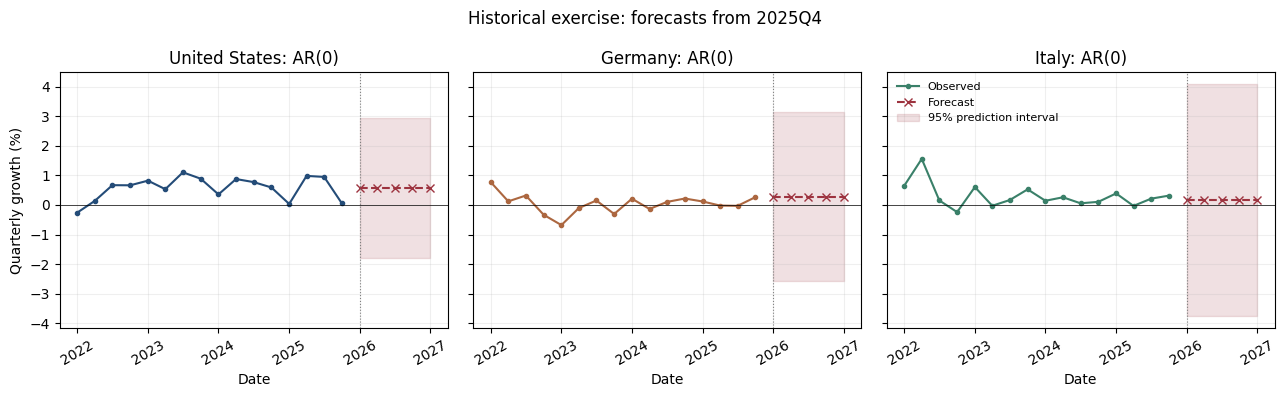

In [12]:
FORECAST_STEPS = 5
future_index = pd.period_range(growth.index[-1] + 1, periods=FORECAST_STEPS, freq="Q")
future_rows, future_forecasts = [], {}
for country, result in fitted.items():
    prediction = result.get_prediction(start=len(growth), end=len(growth) + FORECAST_STEPS - 1)
    means = np.asarray(prediction.predicted_mean)
    intervals = np.asarray(prediction.conf_int(alpha=0.05))
    forecast = pd.DataFrame({"Forecast (%)": means, "95% lower": intervals[:, 0],
                             "95% upper": intervals[:, 1]}, index=future_index)
    future_forecasts[country] = forecast
    for quarter, row in forecast.iterrows():
        future_rows.append({"Country": country, "Quarter": quarter, **row.to_dict()})
future_table = pd.DataFrame(future_rows).set_index(["Country", "Quarter"])
display(future_table.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, country in zip(axes, countries):
    historical = growth[country].iloc[-16:]
    future = future_forecasts[country]
    dates = future.index.to_timestamp()
    ax.plot(historical.index.to_timestamp(), historical, color=colors[country], marker="o", markersize=3, label="Observed")
    ax.plot(dates, future["Forecast (%)"], color="#9d333f", marker="x", linestyle="--", label="Forecast")
    ax.fill_between(dates, future["95% lower"], future["95% upper"], color="#9d333f", alpha=0.15, label="95% prediction interval")
    ax.axvline(dates[0], color="grey", linewidth=0.8, linestyle=":")
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set(title=f"{country}: AR({selected_order[country]})", xlabel="Date")
    ax.grid(alpha=0.2)
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Quarterly growth (%)")
axes[-1].legend(frameon=False, fontsize=8)
fig.suptitle("Historical exercise: forecasts from 2025Q4")
fig.tight_layout()
plt.show()

With AR(0) selected, both the point forecast and the conditional innovation
variance are constant across horizons. A flat forecast reflects the fitted
conditional mean; it does not predict that realised growth will be constant.
The unusually large 2020 observations contribute to the estimated innovation
variance and the width of these full-sample intervals.

The forecast origin precedes the retrieval date, and values for some forecast
quarters were already published by retrieval. They are deliberately outside
this frozen dataset. These forecasts demonstrate the calculation, rather than
claiming to be predictions made in real time.